# The ROI Trap: Capital Equipment Decisions for the Lab
### ROI vs. Payback vs. IRR vs. NPV, and why WACC decides the answer

**Instructor:** Dr. Owasu Brown (PhD, Data Science · MBA · Certificate in Healthcare Finance)

This notebook is the companion to the YouTube video. Every number you see on screen in the video is produced here.

**What you will build**

| Part | Question it answers | Main visuals |
|---|---|---|
| 1. Toolkit | How do we compute each metric? | Formula table |
| 2. WACC | What does money cost each lab? | Stacked WACC bars |
| 3. Scenario 1 | Same $1M analyzer, three labs: who should buy it? | Timeline, PV table, cumulative curves, NPV profile, heatmap |
| 4. The ROI problem | Why does ROI mislead? | Discount-factor decay, metric clusters |
| 5. Scenario 2 | Big project vs. tiny project: the scale trap | Four-panel chart, NPV profiles |
| 6. Lab portfolio | Twelve equipment requests, one budget: which rule picks best? | Rank table, k-means clusters, budget comparison |
| 7. Risk | What if savings or instrument life fall short? | Monte Carlo distributions |
| 8. Handoff | What should a lab manager use? | Summary table, Excel export |

> **How to use it:** run the cells top to bottom (Shift + Enter). Change any number in a cell marked **✏️ INPUT** and re-run to see the decision change.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 0. Setup
Install once from a terminal (or uncomment the first line to install from inside Jupyter):

```bash
pip install numpy numpy-financial pandas matplotlib seaborn scikit-learn openpyxl
```

In [ ]:
# !pip install numpy numpy-financial pandas matplotlib seaborn scikit-learn openpyxl

import itertools
import numpy as np
import numpy_financial as npf          # finance functions: npf.npv, npf.irr
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from IPython.display import display

# ---- One consistent visual style for every chart in the notebook ----
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"   # company / project identity colors
POS, NEG = "#2a78d6", "#e34948"                        # value created (blue) vs destroyed (red)
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e1e0d9"

plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "legend.frameon": False, "font.size": 10,
})
dollars = mtick.FuncFormatter(lambda x, _: f"-${abs(x):,.0f}" if x < 0 else f"${x:,.0f}")
thousands = mtick.FuncFormatter(lambda x, _: f"-${abs(x)/1e3:,.0f}K" if x < 0 else f"${x/1e3:,.0f}K")
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
print("Libraries loaded.")

Libraries loaded.


## 1. The decision toolkit
Five small functions do all the work. Each one answers a different question:

| Metric | Question | Formula | Uses time value? | Uses WACC? |
|---|---|---|---|---|
| Simple ROI | What % profit over the whole life? | (Σ inflows − outlay) ÷ outlay | No | No |
| Payback | How many years to get my money back? | Years until cumulative cash ≥ 0 | No | No |
| Discounted payback | Same, in today's dollars | Years until cumulative PV ≥ 0 | Yes | Yes |
| IRR | What annual % does the project earn? | Rate r where NPV = 0 | Yes | Compared to it |
| NPV | How many dollars of value today? | Σ CFₜ ÷ (1 + WACC)ᵗ − outlay | Yes | Built in |

**Cash flow convention:** a list where position 0 is today (the purchase, negative) and positions 1…n are the yearly cash the instrument saves or earns.

In [ ]:
def wacc(equity_share, cost_equity, cost_debt, tax_rate=0.25):
    '''Weighted average cost of capital. equity_share is E/V (debt share is the rest).'''
    debt_share = 1 - equity_share
    return equity_share * cost_equity + debt_share * cost_debt * (1 - tax_rate)

def simple_roi(flows):
    '''Total profit over the life divided by the outlay. Ignores timing and cost of money.'''
    outlay = -flows[0]
    return (sum(flows[1:]) - outlay) / outlay

def payback(flows, rate=None):
    '''Years to recover the outlay. Pass a rate to get the DISCOUNTED payback.
    Returns np.nan if the money is never recovered within the project life.'''
    f = np.array(flows, dtype=float)
    if rate is not None:
        f = f / (1 + rate) ** np.arange(len(f))       # convert each year to today's dollars
    cum = np.cumsum(f)
    if cum[-1] < 0:
        return np.nan
    yr = np.where(cum >= 0)[0][0]                      # first year the running total turns positive
    return yr - 1 + (-cum[yr - 1] / f[yr])             # + the fraction of that year needed

def evaluate(flows, rate):
    '''All metrics for one cash-flow stream at one discount rate (WACC).'''
    npv = npf.npv(rate, flows)                         # npf.npv treats flows[0] as today (t = 0)
    return {
        "ROI": simple_roi(flows),
        "Payback (yrs)": payback(flows),
        "Disc. payback (yrs)": payback(flows, rate),
        "IRR": npf.irr(flows),
        "NPV ($)": npv,
        "Profitability index": 1 + npv / -flows[0],
    }

# Quick self-test on a textbook case: -$100 then $60 for 2 years at 10%
print({k: round(v, 4) for k, v in evaluate([-100, 60, 60], 0.10).items()})

{'ROI': 0.2, 'Payback (yrs)': np.float64(1.6667), 'Disc. payback (yrs)': np.float64(1.9167), 'IRR': 0.1307, 'NPV ($)': np.float64(4.1322), 'Profitability index': np.float64(1.0413)}


## 2. Step 1 — What does money cost each lab? (WACC)

$$\text{WACC} = \frac{E}{V}R_e + \frac{D}{V}R_d(1-t)$$

Three organizations are considering the same instrument. Their cost of capital is very different because lenders and investors see very different risk.

> **Healthcare note:** a nonprofit hospital lab pays no income tax, so set `tax_rate=0` (no tax shield). Its cost of debt is often lower anyway because many nonprofits can issue tax-exempt bonds.

In [ ]:
# ✏️ INPUT: capital structure for each organization
labs = pd.DataFrame({
    "Lab profile":   ["Large pharma QC lab", "Mid-sized contract research lab", "Venture-backed biotech startup"],
    "Equity share":  [0.50, 0.50, 0.80],
    "Cost of equity":[0.070, 0.140, 0.245],
    "Cost of debt":  [0.040, 0.080, 0.160],
}, index=["Company A", "Company B", "Company C"])
TAX = 0.25

labs["Debt share"] = 1 - labs["Equity share"]
labs["Equity part"] = labs["Equity share"] * labs["Cost of equity"]
labs["Debt part (after tax)"] = labs["Debt share"] * labs["Cost of debt"] * (1 - TAX)
labs["WACC"] = [wacc(r["Equity share"], r["Cost of equity"], r["Cost of debt"], TAX) for _, r in labs.iterrows()]

display(labs[["Lab profile", "Equity share", "Debt share", "Cost of equity", "Cost of debt", "WACC"]]
        .style.format({c: "{:.1%}" for c in ["Equity share", "Debt share", "Cost of equity", "Cost of debt", "WACC"]})
        .set_caption("Table 1. Capital structure and WACC by lab")
        .background_gradient(subset=["WACC"], cmap="Blues"))

,Lab profile,Equity share,Debt share,Cost of equity,Cost of debt,WACC
Company A,Large pharma QC lab,50.0%,50.0%,7.0%,4.0%,5.0%
Company B,Mid-sized contract research lab,50.0%,50.0%,14.0%,8.0%,10.0%
Company C,Venture-backed biotech startup,80.0%,20.0%,24.5%,16.0%,22.0%


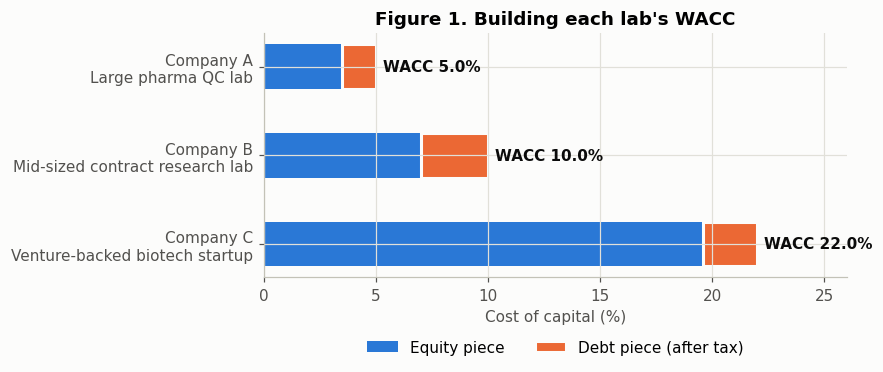

In [ ]:
# Chart: where each lab's WACC comes from (equity piece + after-tax debt piece)
fig, ax = plt.subplots(figsize=(8, 3.6))
y = np.arange(len(labs))
ax.barh(y, labs["Equity part"] * 100, color=BLUE, height=0.5, label="Equity piece")
ax.barh(y, labs["Debt part (after tax)"] * 100, left=labs["Equity part"] * 100,
        color=ORANGE, height=0.5, label="Debt piece (after tax)", edgecolor="#fcfcfb", linewidth=2)
for i, w in enumerate(labs["WACC"]):
    ax.text(w * 100 + 0.3, i, f"WACC {w:.1%}", va="center", fontweight="bold", color=INK)
ax.set_yticks(y, [f"{i}\n{p}" for i, p in zip(labs.index, labs['Lab profile'])])
ax.invert_yaxis()
ax.set_xlabel("Cost of capital (%)")
ax.set_xlim(0, 26)
ax.set_title("Figure 1. Building each lab's WACC")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2)
plt.tight_layout(); plt.show()

WACCS = labs["WACC"].to_dict()     # {'Company A': 0.05, 'Company B': 0.10, 'Company C': 0.22}
COLORS = dict(zip(labs.index, [BLUE, ORANGE, AQUA]))

## 3. Scenario 1 — Same analyzer, three labs

A high-throughput analyzer that automates sample prep and testing:

* **Price today (Year 0):** $1,000,000
* **Net cash each year, Years 1–5:** $270,000 (lower labor, less reagent waste, fewer send-out tests)

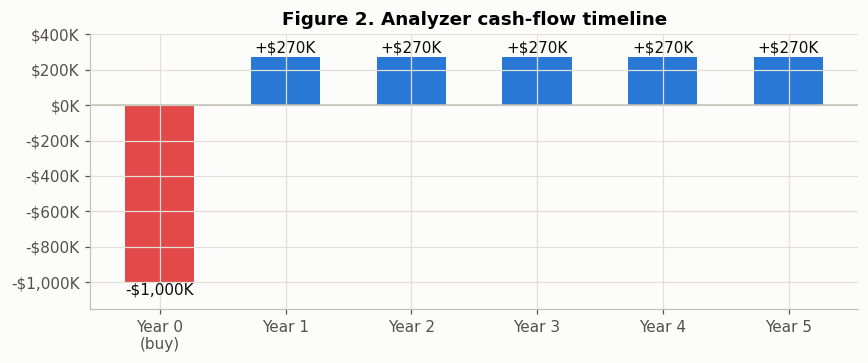

In [ ]:
# ✏️ INPUT: the instrument's cash flows
OUTLAY, ANNUAL, YEARS = 1_000_000, 270_000, 5
analyzer = [-OUTLAY] + [ANNUAL] * YEARS

fig, ax = plt.subplots(figsize=(8, 3.4))
bars = ax.bar(range(YEARS + 1), analyzer, color=[NEG] + [POS] * YEARS, width=0.55)
for b, v in zip(bars, analyzer):
    ax.text(b.get_x() + b.get_width() / 2, v + (25_000 if v > 0 else -70_000),
            f"{'-' if v < 0 else '+'}${abs(v)/1e3:,.0f}K", ha="center", color=INK)
ax.axhline(0, color="#c3c2b7", lw=1)
ax.set_xticks(range(YEARS + 1), ["Year 0\n(buy)"] + [f"Year {t}" for t in range(1, YEARS + 1)])
ax.yaxis.set_major_formatter(thousands)
ax.set_ylim(-1_150_000, 400_000)
ax.set_title("Figure 2. Analyzer cash-flow timeline")
plt.tight_layout(); plt.show()

### Steps 2–4: ROI, payback and IRR (the metrics that ignore who is buying)

In [ ]:
s1 = pd.DataFrame({name: evaluate(analyzer, r) for name, r in WACCS.items()}).T
s1.insert(0, "WACC", pd.Series(WACCS))
s1["Decision"] = np.where(s1["NPV ($)"] > 50_000, "Strong accept",
                  np.where(s1["NPV ($)"] > 0, "Marginal accept", "Reject"))

blind = s1[["ROI", "Payback (yrs)", "IRR"]]
display(blind.style.format({"ROI": "{:.1%}", "Payback (yrs)": "{:.2f}", "IRR": "{:.2%}"})
        .set_caption("Table 2. The 'blind' metrics: identical for every lab"))
print("Worked ROI:     (5 × $270,000 − $1,000,000) ÷ $1,000,000 =", f"{simple_roi(analyzer):.0%}")
print("Worked payback: 3 full years recover $810,000; $190,000 ÷ $270,000 = 0.70 → 3.70 years")
print(f"IRR:            {npf.irr(analyzer):.2%}  (a property of the PROJECT, not the lab)")

,ROI,Payback (yrs),IRR
Company A,35.0%,3.70,10.92%
Company B,35.0%,3.70,10.92%
Company C,35.0%,3.70,10.92%


Worked ROI:     (5 × $270,000 − $1,000,000) ÷ $1,000,000 = 35%
Worked payback: 3 full years recover $810,000; $190,000 ÷ $270,000 = 0.70 → 3.70 years
IRR:            10.92%  (a property of the PROJECT, not the lab)


### Step 5: NPV — discount every year at each lab's WACC

In [ ]:
# Present value of each year's cash, by lab
pv = pd.DataFrame({name: [cf / (1 + r) ** t for t, cf in enumerate(analyzer)] for name, r in WACCS.items()},
                  index=[f"Year {t}" for t in range(YEARS + 1)])
pv.insert(0, "Cash flow", analyzer)
pv.loc["NPV (sum)"] = pv.sum()
pv.loc["NPV (sum)", "Cash flow"] = np.nan

display(pv.style.format(lambda v: "" if pd.isna(v) else (f"-${abs(v):,.0f}" if v < 0 else f"${v:,.0f}"))
        .set_caption("Table 3. Present value of each payment (today's dollars)")
        .map(lambda v: f"color: {NEG}; font-weight: bold" if isinstance(v, float) and v < 0 else "",
             subset=pd.IndexSlice[["NPV (sum)"], :]))

,Cash flow,Company A,Company B,Company C
Year 0,"-$1,000,000","-$1,000,000","-$1,000,000","-$1,000,000"
Year 1,"$270,000","$257,143","$245,455","$221,311"
Year 2,"$270,000","$244,898","$223,140","$181,403"
Year 3,"$270,000","$233,236","$202,855","$148,691"
Year 4,"$270,000","$222,130","$184,414","$121,878"
Year 5,"$270,000","$211,552","$167,649","$99,900"
NPV (sum),,"$168,959","$23,512","-$226,817"


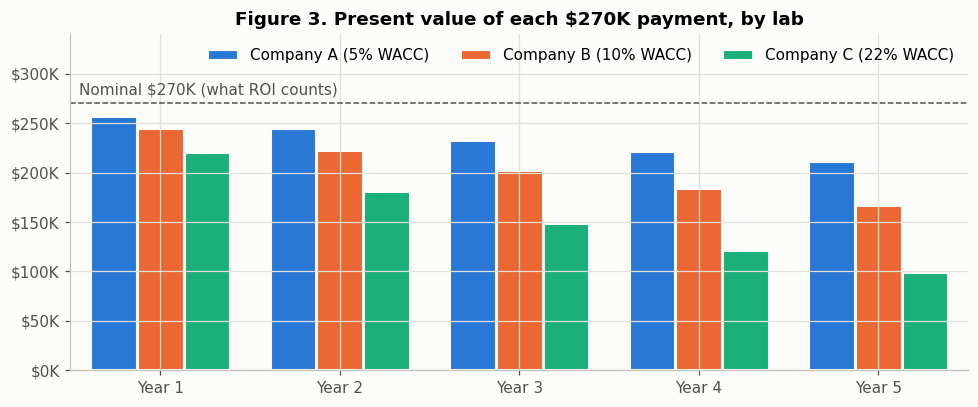

In [ ]:
# Clustered bars: the same $270K payment is worth less each year, and much less at a high WACC
fig, ax = plt.subplots(figsize=(9, 3.8))
x, w = np.arange(1, YEARS + 1), 0.26
for i, name in enumerate(WACCS):
    ax.bar(x + (i - 1) * w, pv[name].iloc[1:YEARS + 1], w, color=COLORS[name],
           label=f"{name} ({WACCS[name]:.0%} WACC)", edgecolor="#fcfcfb", linewidth=2)
ax.axhline(ANNUAL, color=MUTED, ls="--", lw=1)
ax.text(0.55, ANNUAL + 6_000, "Nominal $270K (what ROI counts)", va="bottom", color=MUTED)
ax.set_xticks(x, [f"Year {t}" for t in x])
ax.yaxis.set_major_formatter(thousands)
ax.set_xlim(0.5, YEARS + 0.5); ax.set_ylim(0, 340_000)
ax.set_title("Figure 3. Present value of each $270K payment, by lab")
ax.legend(loc="upper right", ncol=3)
plt.tight_layout(); plt.show()

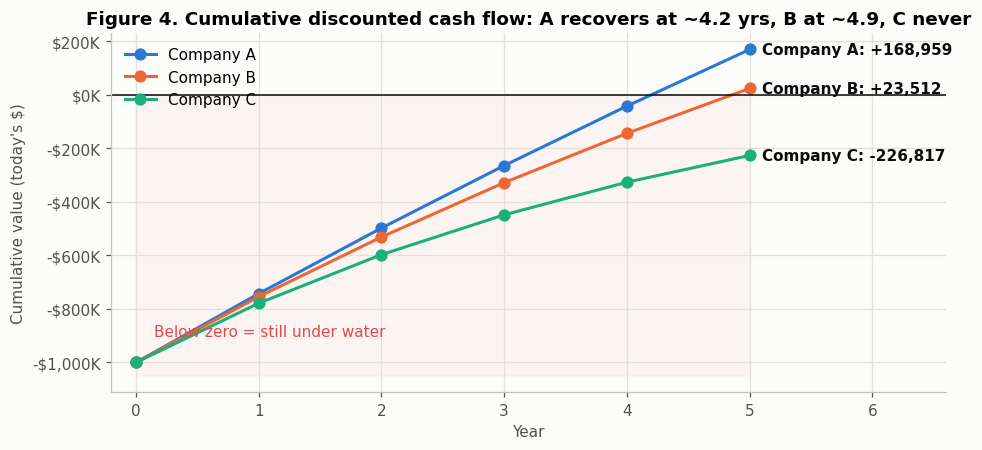

In [ ]:
# Cumulative discounted cash: where each line crosses zero = discounted payback
fig, ax = plt.subplots(figsize=(9, 4.2))
yrs = np.arange(YEARS + 1)
for name in WACCS:
    cum = np.cumsum(pv[name].iloc[:YEARS + 1])
    ax.plot(yrs, cum, marker="o", ms=7, lw=2, color=COLORS[name], label=name)
    ax.annotate(f"{name}: {cum.iloc[-1]:+,.0f}", (YEARS, cum.iloc[-1]), xytext=(8, 0),
                textcoords="offset points", va="center", color=INK, fontweight="bold")
ax.axhline(0, color=INK, lw=1)
ax.fill_between(yrs, 0, -1_050_000, color=NEG, alpha=0.04)
ax.text(0.15, -900_000, "Below zero = still under water", color=NEG)
ax.yaxis.set_major_formatter(thousands)
ax.set_xlim(-0.2, YEARS + 1.6)
ax.set_xlabel("Year"); ax.set_ylabel("Cumulative value (today's $)")
ax.set_title("Figure 4. Cumulative discounted cash flow: A recovers at ~4.2 yrs, B at ~4.9, C never")
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

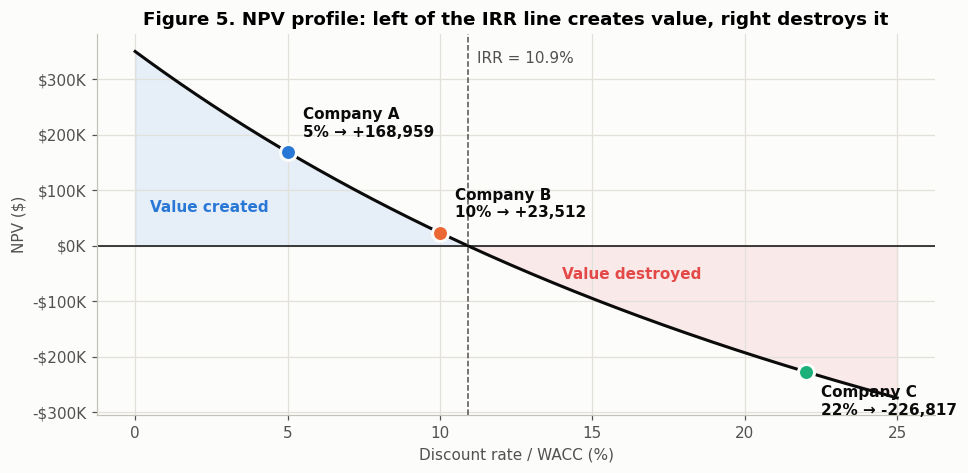

In [ ]:
# The NPV profile: the single most useful chart in capital budgeting
rates = np.linspace(0, 0.25, 251)
profile = [npf.npv(r, analyzer) for r in rates]
irr = npf.irr(analyzer)

fig, ax = plt.subplots(figsize=(9, 4.4))
ax.plot(rates * 100, profile, color=INK, lw=2, label="Analyzer NPV at each cost of capital")
ax.fill_between(rates * 100, profile, 0, where=np.array(profile) > 0, color=POS, alpha=0.10)
ax.fill_between(rates * 100, profile, 0, where=np.array(profile) < 0, color=NEG, alpha=0.10)
ax.axhline(0, color=INK, lw=1)
ax.axvline(irr * 100, color=MUTED, ls="--", lw=1)
ax.text(irr * 100 + 0.3, 330_000, f"IRR = {irr:.1%}", color=MUTED)
for name, r in WACCS.items():
    v = npf.npv(r, analyzer)
    ax.scatter(r * 100, v, s=110, color=COLORS[name], zorder=5, edgecolor="#fcfcfb", linewidth=2)
    ax.annotate(f"{name}\n{r:.0%} → {v:+,.0f}", (r * 100, v), xytext=(10, 10 if v > 0 else -28),
                textcoords="offset points", fontweight="bold", color=INK)
ax.text(0.5, 60_000, "Value created", color=POS, fontweight="bold")
ax.text(14, -60_000, "Value destroyed", color=NEG, fontweight="bold")
ax.yaxis.set_major_formatter(thousands)
ax.set_xlabel("Discount rate / WACC (%)"); ax.set_ylabel("NPV ($)")
ax.set_title("Figure 5. NPV profile: left of the IRR line creates value, right destroys it")
plt.tight_layout(); plt.show()

In [ ]:
# Final Scenario 1 scorecard
display(s1.style.format({"WACC": "{:.1%}", "ROI": "{:.1%}", "Payback (yrs)": "{:.2f}",
                         "Disc. payback (yrs)": lambda v: "Never" if pd.isna(v) else f"{v:.2f}",
                         "IRR": "{:.2%}", "NPV ($)": lambda v: f"-${abs(v):,.0f}" if v < 0 else f"+${v:,.0f}",
                         "Profitability index": "{:.2f}"})
        .set_caption("Table 4. Scenario 1 scorecard: only the NPV-based rows change")
        .map(lambda v: f"background-color: #fde4e3; color: {NEG}; font-weight: bold" if v == "Reject"
             else ("background-color: #e3eefb; font-weight: bold" if isinstance(v, str) else ""),
             subset=["Decision"]))

,WACC,ROI,Payback (yrs),Disc. payback (yrs),IRR,NPV ($),Profitability index,Decision
Company A,5.0%,35.0%,3.70,4.20,10.92%,"+$168,959",1.17,Strong accept
Company B,10.0%,35.0%,3.70,4.86,10.92%,"+$23,512",1.02,Marginal accept
Company C,22.0%,35.0%,3.70,Never,10.92%,"-$226,817",0.77,Reject


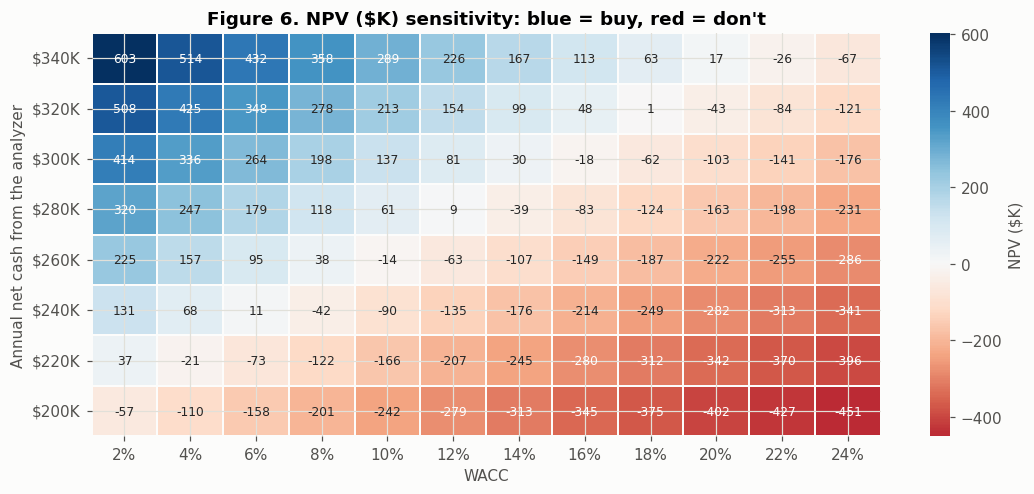

In [ ]:
# Heatmap: NPV across many WACCs and many savings assumptions (what-if grid)
w_grid = np.arange(0.02, 0.245, 0.02)
s_grid = np.arange(200_000, 345_000, 20_000)
grid = pd.DataFrame([[npf.npv(w, [-OUTLAY] + [s] * YEARS) / 1e3 for w in w_grid] for s in s_grid],
                    index=[f"${s/1e3:,.0f}K" for s in s_grid], columns=[f"{w:.0%}" for w in w_grid])

fig, ax = plt.subplots(figsize=(10, 4.6))
sns.heatmap(grid.iloc[::-1], annot=True, fmt=".0f", cmap="RdBu", center=0, linewidths=1,
            linecolor="#fcfcfb", cbar_kws={"label": "NPV ($K)"}, ax=ax, annot_kws={"size": 8})
ax.set_xlabel("WACC"); ax.set_ylabel("Annual net cash from the analyzer")
ax.set_title("Figure 6. NPV ($K) sensitivity: blue = buy, red = don't")
plt.tight_layout(); plt.show()

## 4. Why ROI thinking breaks down

1. **It ignores time.** A dollar in Year 5 counts the same as a dollar today.
2. **It ignores what money costs.** 35% for every lab, whether money costs 5% or 22%.
3. **It can approve value-destroying deals.** Company C sees 35% ROI and a 3.7-year payback, and loses about $227K of value.
4. **It's a multi-year number that sounds annual.** 35% over five years is about 10.9% per year (the IRR).

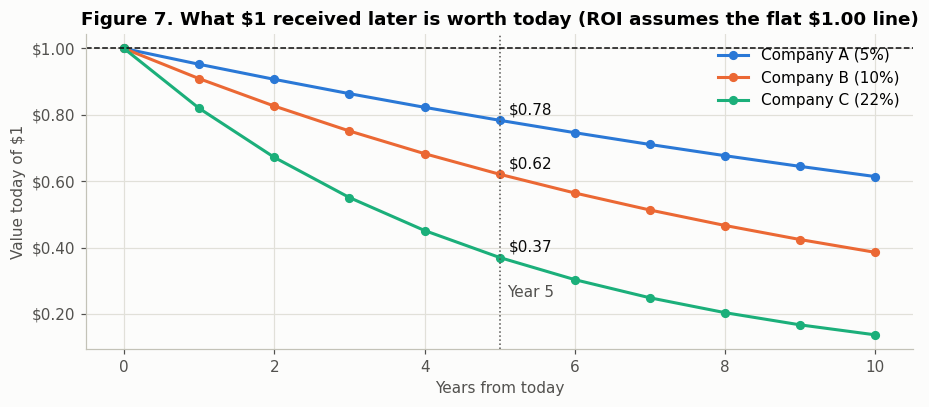

In [ ]:
# How fast a future dollar loses value at each WACC
t = np.arange(0, 11)
fig, ax = plt.subplots(figsize=(8.5, 3.8))
for name, r in WACCS.items():
    d = 1 / (1 + r) ** t
    ax.plot(t, d, marker="o", ms=5, lw=2, color=COLORS[name], label=f"{name} ({r:.0%})")
    ax.annotate(f"${d[5]:.2f}", (5, d[5]), xytext=(6, 4), textcoords="offset points", color=INK)
ax.axvline(5, color=MUTED, ls=":", lw=1)
ax.text(5.1, 0.25, "Year 5", color=MUTED)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"${v:.2f}"))
ax.set_xlabel("Years from today"); ax.set_ylabel("Value today of \\$1")
ax.set_title("Figure 7. What \\$1 received later is worth today (ROI assumes the flat \\$1.00 line)")
ax.axhline(1, color=INK, lw=1, ls="--")
ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

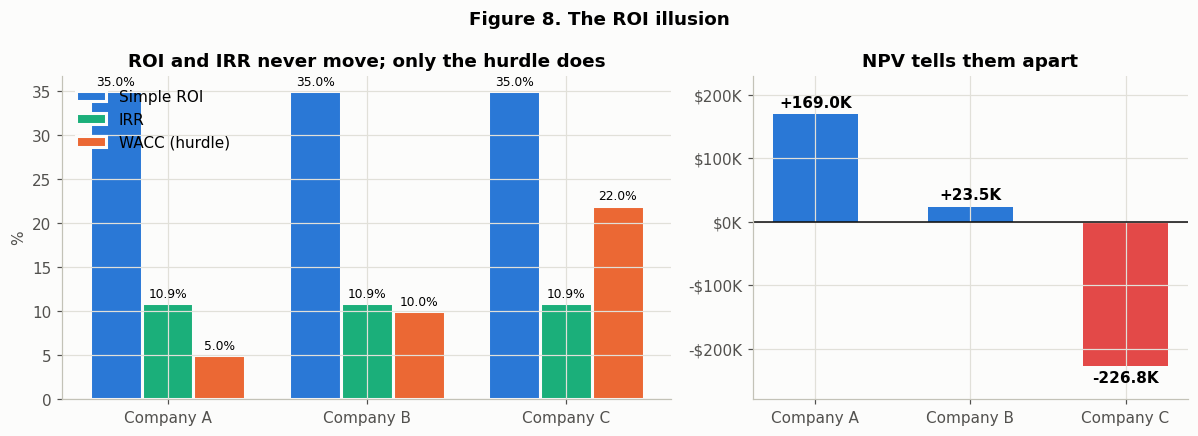

In [ ]:
# Metric clusters: the 'percent' metrics stand still while NPV swings
fig, axes = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1.4, 1]})
ax = axes[0]
metrics = {"Simple ROI": s1["ROI"] * 100, "IRR": s1["IRR"] * 100, "WACC (hurdle)": s1["WACC"] * 100}
x, w = np.arange(3), 0.26
for i, (lbl, vals) in enumerate(metrics.items()):
    b = ax.bar(x + (i - 1) * w, vals, w, color=[BLUE, AQUA, ORANGE][i], label=lbl, edgecolor="#fcfcfb", lw=2)
    ax.bar_label(b, fmt="%.1f%%", fontsize=8, padding=2)
ax.set_xticks(x, s1.index); ax.set_ylabel("%")
ax.set_title("ROI and IRR never move; only the hurdle does"); ax.legend(loc="upper left")

ax = axes[1]
npvs = s1["NPV ($)"]
b = ax.bar(s1.index, npvs, color=[POS if v > 0 else NEG for v in npvs], width=0.55)
ax.bar_label(b, labels=[f"{v/1e3:+,.1f}K" for v in npvs], padding=3, fontweight="bold")
ax.axhline(0, color=INK, lw=1)
ax.yaxis.set_major_formatter(thousands)
ax.set_ylim(-280_000, 230_000)
ax.set_title("NPV tells them apart")
fig.suptitle("Figure 8. The ROI illusion", fontweight="bold")
plt.tight_layout(); plt.show()

## 5. Scenario 2 — The scale trap (NPV vs. IRR, ROI and payback)

One lab, **10% WACC**, capital available, and **room for only one project** (same bench space, same techs):

* **Project A:** automate a high-volume assay. Invest **$100,000**, save **$50,000/yr for 10 years**.
* **Project B:** a micro-fix. Invest **$1**, get **$0.60/yr for 10 years**. (Deliberately absurd, so the lesson is unmissable.)

In [ ]:
# ✏️ INPUT
RATE2 = 0.10
proj = {"Project A ($100K assay automation)": [-100_000] + [50_000] * 10,
        "Project B ($1 micro-fix)":           [-1.00] + [0.60] * 10}

s2 = pd.DataFrame({k: evaluate(v, RATE2) for k, v in proj.items()}).T
s2["Picks"] = ""
winner = {"ROI": s2["ROI"].idxmax(), "Payback (yrs)": s2["Payback (yrs)"].idxmin(),
          "IRR": s2["IRR"].idxmax(), "NPV ($)": s2["NPV ($)"].idxmax()}
tally = pd.DataFrame({"Metric": list(winner), "Winner": [w.split(" (")[0] for w in winner.values()]})

display(s2.drop(columns=["Picks", "Disc. payback (yrs)", "Profitability index"])
        .style.format({"ROI": "{:.0%}", "Payback (yrs)": "{:.2f}", "IRR": "{:.1%}", "NPV ($)": "${:,.2f}"})
        .set_caption("Table 5. Scenario 2 metrics"))
display(tally.style.hide(axis="index").set_caption("Table 6. Which project each metric picks")
        .map(lambda v: "font-weight: bold; color: #2a78d6" if v == "Project A" else "", subset=["Winner"]))

,ROI,Payback (yrs),IRR,NPV ($)
Project A ($100K assay automation),400%,2.00,49.1%,"$207,228.36"
Project B ($1 micro-fix),500%,1.67,59.4%,$2.69


Metric,Winner
ROI,Project B
Payback (yrs),Project B
IRR,Project B
NPV ($),Project A


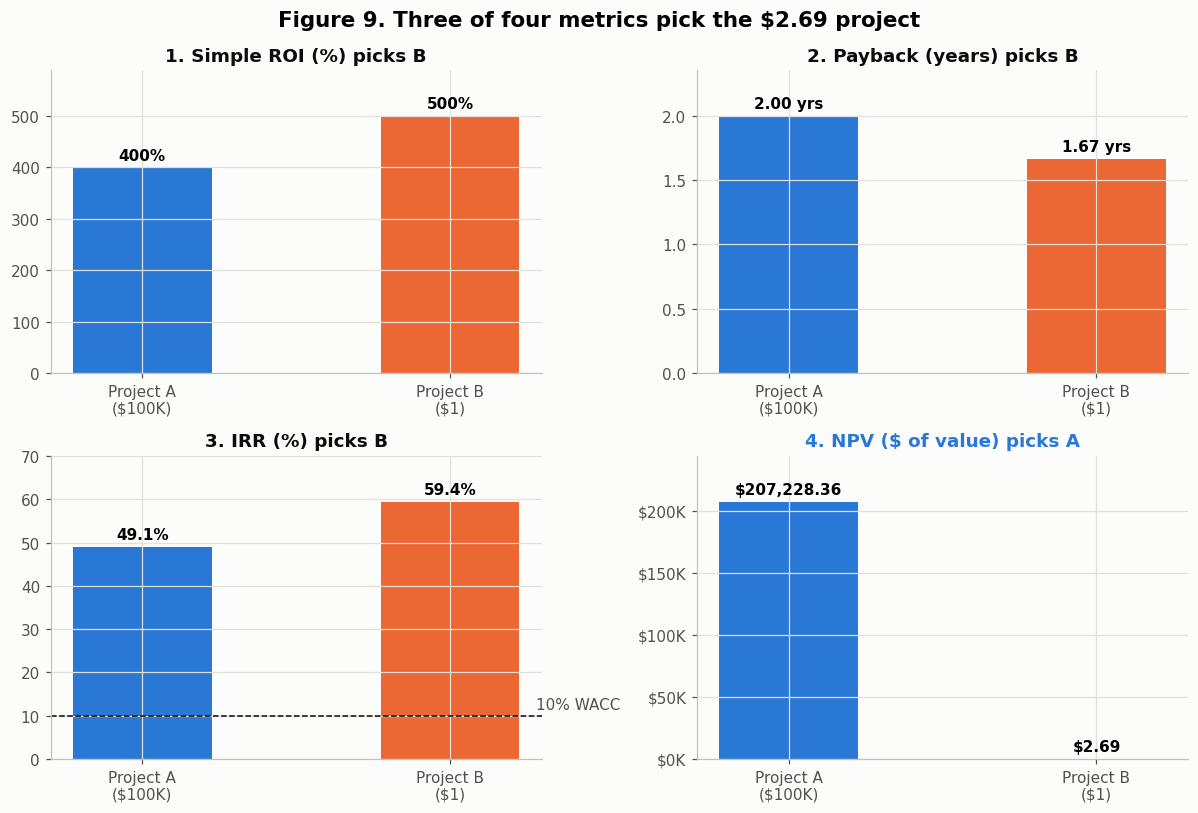

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7.5))
names = ["Project A\n($100K)", "Project B\n($1)"]
panels = [("ROI", 100, "{:.0f}%", "1. Simple ROI (%) picks B"),
          ("Payback (yrs)", 1, "{:.2f} yrs", "2. Payback (years) picks B"),
          ("IRR", 100, "{:.1f}%", "3. IRR (%) picks B"),
          ("NPV ($)", 1, "${:,.2f}", "4. NPV ($ of value) picks A")]
for ax, (col, k, fmt, title) in zip(axes.flat, panels):
    vals = s2[col].values * k
    b = ax.bar(names, vals, color=[BLUE, ORANGE], width=0.45)
    ax.bar_label(b, labels=[fmt.format(v) for v in vals], padding=3, fontweight="bold")
    ax.set_title(title, color=(POS if col == "NPV ($)" else INK))
    ax.margins(y=0.18)
    if col == "IRR":
        ax.axhline(RATE2 * 100, color=INK, ls="--", lw=1); ax.text(1.28, RATE2 * 100 + 1.5, "10% WACC", color=MUTED)
    if col == "NPV ($)":
        ax.yaxis.set_major_formatter(thousands)
fig.suptitle("Figure 9. Three of four metrics pick the $2.69 project", fontweight="bold", fontsize=14)
plt.tight_layout(); plt.show()

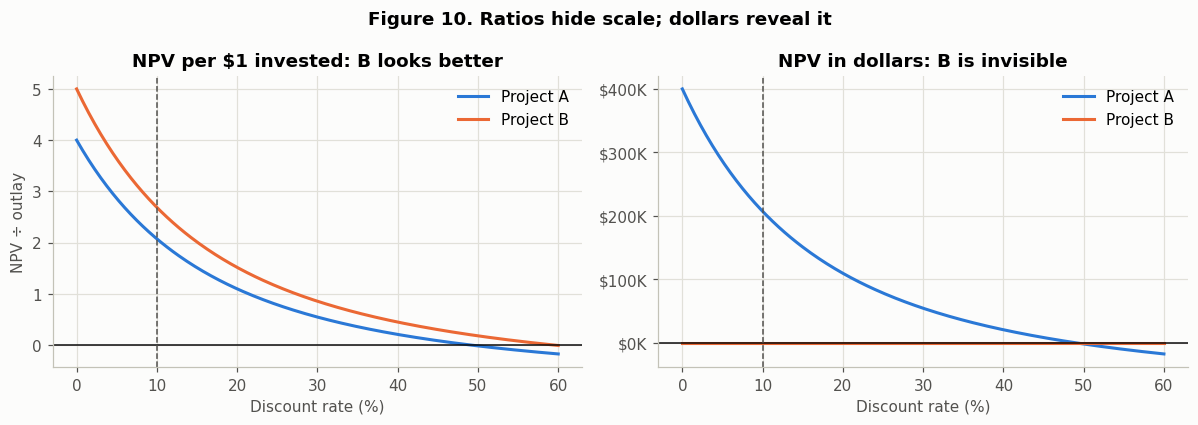

In [ ]:
# Scale-free view: IRR per dollar vs. NPV in dollars across discount rates
rates = np.linspace(0, 0.6, 241)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.9))
for (name, flows), c in zip(proj.items(), [BLUE, ORANGE]):
    prof = [npf.npv(r, flows) for r in rates]
    axes[0].plot(rates * 100, np.array(prof) / -flows[0], color=c, lw=2, label=name.split(" (")[0])
    axes[1].plot(rates * 100, prof, color=c, lw=2, label=name.split(" (")[0])
axes[0].set_title("NPV per $1 invested: B looks better"); axes[0].set_ylabel("NPV ÷ outlay")
axes[1].set_title("NPV in dollars: B is invisible"); axes[1].yaxis.set_major_formatter(thousands)
for ax in axes:
    ax.axhline(0, color=INK, lw=1); ax.axvline(10, color=MUTED, ls="--", lw=1)
    ax.set_xlabel("Discount rate (%)"); ax.legend()
fig.suptitle("Figure 10. Ratios hide scale; dollars reveal it", fontweight="bold")
plt.tight_layout(); plt.show()

## 6. A real lab budget: twelve equipment requests, $2.0M to spend

This is the everyday version of the problem. A lab at a **10% WACC** receives twelve capital requests (illustrative figures) but has only **$2.0M**. We compare four ways of choosing:

* rank by **ROI**, **payback** or **IRR** and fund down the list until the money runs out, versus
* choose the combination with the **highest total NPV** (we test all 4,096 combinations).

Notice the long-life requests (storage, HVAC): ROI adds up 15–20 years of cash without discounting, so they look far better than they are.

Then we use **k-means clustering** to group the requests into natural types.

In [ ]:
# ✏️ INPUT: capital requests (outlay, annual net cash, useful life in years)
requests = pd.DataFrame([
    ("Automated chemistry analyzer", 1_000_000, 270_000, 5),
    ("Liquid-handling robot",           250_000,  80_000, 5),
    ("LIMS upgrade",                    400_000, 110_000, 7),
    ("LC-MS/MS system",                 800_000, 190_000, 8),
    ("Digital pathology scanner",       350_000,  95_000, 6),
    ("Barcode label printers",           15_000,   9_000, 4),
    ("Pipette calibration kit",           5_000,   3_500, 3),
    ("-80°C freezer replacement",        40_000,  12_000, 10),
    ("Automated sample storage",        600_000,  75_000, 15),
    ("Next-gen sequencer",              900_000, 230_000, 6),
    ("Lab HVAC / fume hood upgrade",    500_000,  60_000, 20),
    ("Benchtop qPCR",                   120_000,  30_000, 5),
], columns=["Request", "Outlay", "Annual cash", "Life (yrs)"]).set_index("Request")
BUDGET, RATE = 2_000_000, 0.10

flows_of = lambda r: [-r["Outlay"]] + [r["Annual cash"]] * int(r["Life (yrs)"])
m = pd.DataFrame({name: evaluate(flows_of(r), RATE) for name, r in requests.iterrows()}).T
port = requests.join(m)
for col, asc in [("ROI", False), ("Payback (yrs)", True), ("IRR", False), ("NPV ($)", False)]:
    port[f"Rank by {col.split(' ')[0]}"] = port[col].rank(ascending=asc, method="first").astype(int)

display(port[["Outlay", "ROI", "Payback (yrs)", "IRR", "NPV ($)", "Rank by ROI", "Rank by NPV"]]
        .sort_values("NPV ($)", ascending=False)
        .style.format({"Outlay": "${:,.0f}", "ROI": "{:.0%}", "Payback (yrs)": "{:.2f}", "IRR": "{:.1%}",
                       "NPV ($)": lambda v: f"-${abs(v):,.0f}" if v < 0 else f"${v:,.0f}"})
        .background_gradient(subset=["NPV ($)"], cmap="RdBu", vmin=-port["NPV ($)"].abs().max(),
                             vmax=port["NPV ($)"].abs().max())
        .set_caption("Table 7. Twelve requests at a 10% WACC, sorted by NPV"))

,Outlay,ROI,Payback (yrs),IRR,NPV ($),Rank by ROI,Rank by NPV
Request,,,,,,,
LC-MS/MS system,"$800,000",90%,4.21,17.0%,"$213,636",6,1
LIMS upgrade,"$400,000",92%,3.64,19.7%,"$135,526",5,2
Next-gen sequencer,"$900,000",53%,3.91,13.8%,"$101,710",10,3
Digital pathology scanner,"$350,000",63%,3.68,16.0%,"$63,750",8,4
Liquid-handling robot,"$250,000",60%,3.12,18.0%,"$53,263",9,5
-80°C freezer replacement,"$40,000",200%,3.33,27.3%,"$33,735",1,6
Automated chemistry analyzer,"$1,000,000",35%,3.70,10.9%,"$23,512",11,7
Barcode label printers,"$15,000",140%,1.67,47.2%,"$13,529",2,8
Lab HVAC / fume hood upgrade,"$500,000",140%,8.33,10.3%,"$10,814",3,9


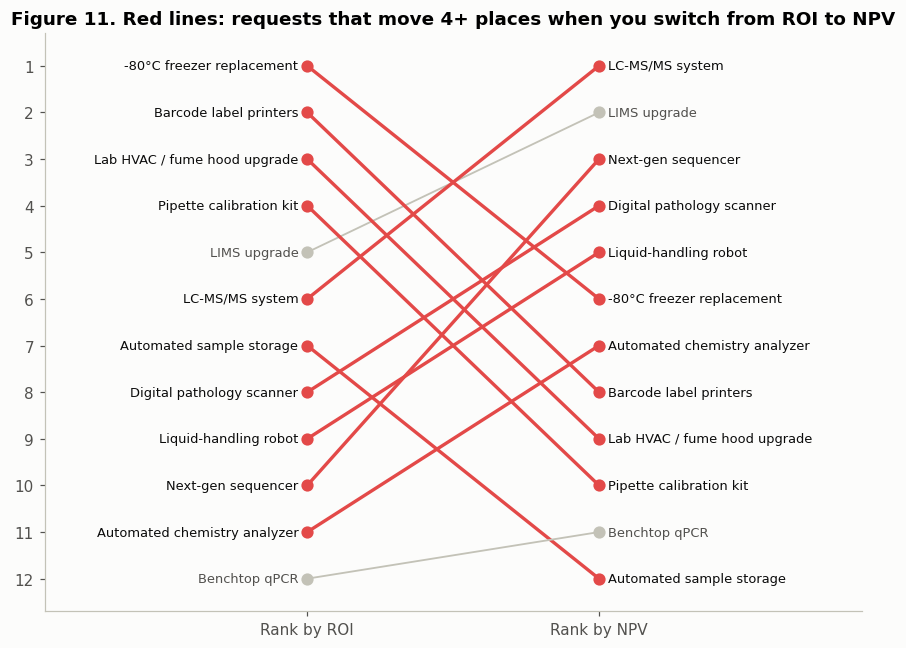

In [ ]:
# Rank-shift chart: where each request lands under ROI vs. NPV
fig, ax = plt.subplots(figsize=(8, 6))
for name, r in port.iterrows():
    moved = abs(r["Rank by ROI"] - r["Rank by NPV"]) >= 4
    c = NEG if moved else "#c3c2b7"
    ax.plot([0, 1], [r["Rank by ROI"], r["Rank by NPV"]], color=c, lw=2.2 if moved else 1.2, marker="o", ms=7)
    ax.text(-0.03, r["Rank by ROI"], name, ha="right", va="center", fontsize=8.5, color=INK if moved else MUTED)
    ax.text(1.03, r["Rank by NPV"], name, ha="left", va="center", fontsize=8.5, color=INK if moved else MUTED)
ax.set_xlim(-0.9, 1.9); ax.set_ylim(12.7, 0.3)
ax.set_xticks([0, 1], ["Rank by ROI", "Rank by NPV"]); ax.set_yticks(range(1, 13))
ax.grid(False)
ax.set_title("Figure 11. Red lines: requests that move 4+ places when you switch from ROI to NPV")
plt.tight_layout(); plt.show()

,Requests,Avg outlay,Avg ROI,Avg IRR,Avg payback,Total NPV
Cluster name,,,,,,
Small quick wins,3,"$20,000",150%,41.1%,2.14,"$50,968"
Strategic value creators,3,"$700,000",79%,16.8%,3.92,"$450,872"
Thin margins: stress-test,6,"$470,000",68%,12.1%,5.14,"$115,519"


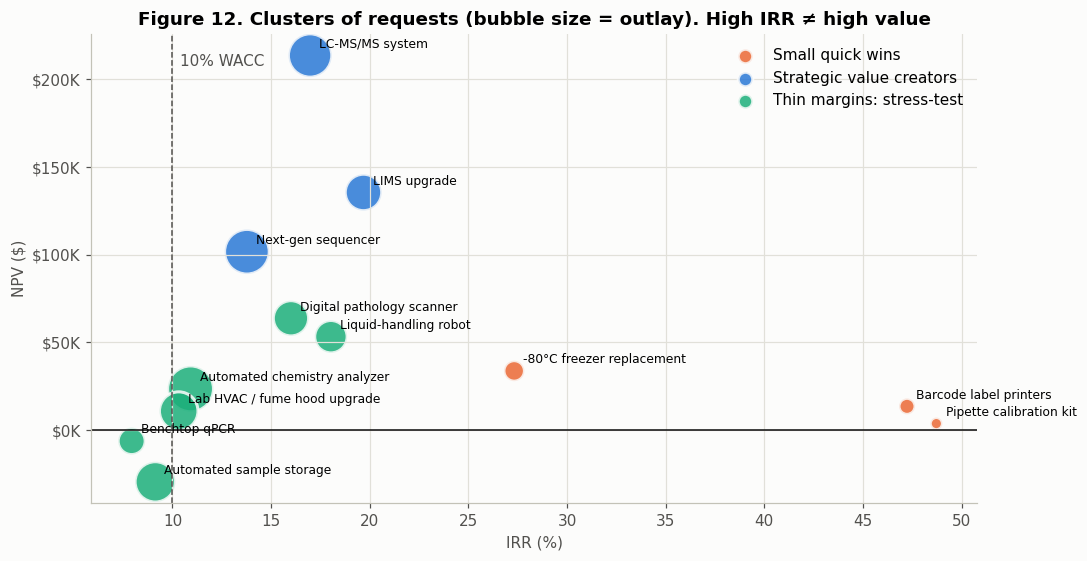

In [ ]:
# k-means clustering: what natural types of request are there?
# Three features: size of the check, value per dollar invested, and total value
features = pd.DataFrame({
    "log outlay": np.log10(port["Outlay"]),        # log so a $5K kit and a $1M analyzer are comparable
    "NPV per $": port["NPV ($)"] / port["Outlay"],
    "NPV ($K)": port["NPV ($)"] / 1e3,
})
X = StandardScaler().fit_transform(features)            # put every feature on the same scale
km = KMeans(n_clusters=3, n_init=20, random_state=42).fit(X)
port["Cluster"] = km.labels_

# Name clusters by their profile (highest average NPV, smallest average outlay, the rest)
prof = port.groupby("Cluster").agg(npv=("NPV ($)", "mean"), outlay=("Outlay", "mean"))
big = prof["npv"].idxmax()
small = prof.drop(big)["outlay"].idxmin()
names = {big: "Strategic value creators", small: "Small quick wins"}
names.update({c: "Thin margins: stress-test" for c in prof.index if c not in names})
port["Cluster name"] = port["Cluster"].map(names)

summary = port.groupby("Cluster name").agg(Requests=("Outlay", "size"), **{
    "Avg outlay": ("Outlay", "mean"), "Avg ROI": ("ROI", "mean"), "Avg IRR": ("IRR", "mean"),
    "Avg payback": ("Payback (yrs)", "mean"), "Total NPV": ("NPV ($)", "sum")})
display(summary.style.format({"Avg outlay": "${:,.0f}", "Avg ROI": "{:.0%}", "Avg IRR": "{:.1%}",
                              "Avg payback": "{:.2f}", "Total NPV": "${:,.0f}"})
        .set_caption("Table 8. k-means clusters of the twelve requests"))

CL_COL = {"Strategic value creators": BLUE, "Small quick wins": ORANGE, "Thin margins: stress-test": AQUA}
fig, ax = plt.subplots(figsize=(10, 5.2))
for cname, g in port.groupby("Cluster name"):
    ax.scatter(g["IRR"] * 100, g["NPV ($)"], s=np.sqrt(g["Outlay"]) * 0.9, color=CL_COL[cname],
               alpha=0.85, edgecolor="#fcfcfb", linewidth=2, label=cname)
for name, r in port.iterrows():
    ax.annotate(name, (r["IRR"] * 100, r["NPV ($)"]), xytext=(6, 5), textcoords="offset points", fontsize=8)
ax.axhline(0, color=INK, lw=1); ax.axvline(RATE * 100, color=MUTED, ls="--", lw=1)
ax.text(RATE * 100 + 0.4, ax.get_ylim()[1] * 0.92, "10% WACC", color=MUTED)
ax.yaxis.set_major_formatter(thousands)
ax.set_xlabel("IRR (%)"); ax.set_ylabel("NPV ($)")
ax.set_title("Figure 12. Clusters of requests (bubble size = outlay). High IRR ≠ high value")
leg = ax.legend(loc="upper right")
for h in leg.legend_handles: h.set_sizes([90])
plt.tight_layout(); plt.show()

,Projects funded,Capital spent,Total NPV,Funded
Rank by ROI,7,"$1,880,000","$404,667","-80°C freezer replacement, Barcode label printers, Lab HVAC / fume hood upgrade, Pipette calibration kit, LIMS upgrade, LC-MS/MS system, Benchtop qPCR"
Rank by payback,7,"$1,960,000","$405,216","Pipette calibration kit, Barcode label printers, Liquid-handling robot, -80°C freezer replacement, LIMS upgrade, Digital pathology scanner, Next-gen sequencer"
Rank by IRR,8,"$1,980,000","$510,866","Pipette calibration kit, Barcode label printers, -80°C freezer replacement, LIMS upgrade, Liquid-handling robot, LC-MS/MS system, Digital pathology scanner, Benchtop qPCR"
Maximize NPV,7,"$1,860,000","$517,142","Liquid-handling robot, LIMS upgrade, LC-MS/MS system, Digital pathology scanner, Barcode label printers, Pipette calibration kit, -80°C freezer replacement"


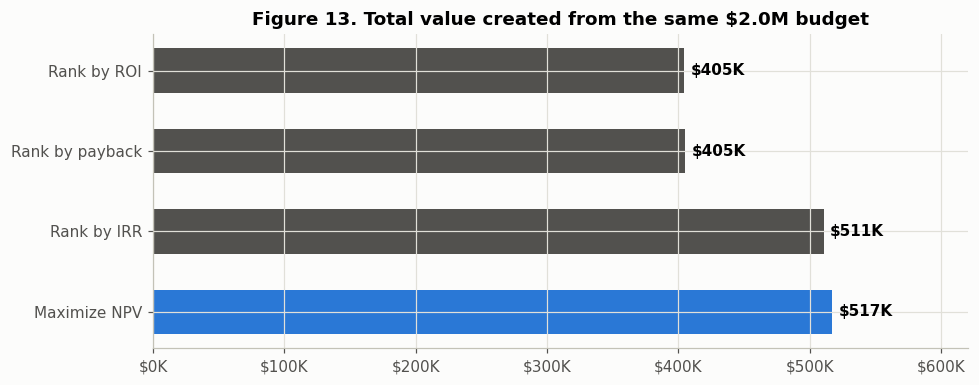

In [ ]:
# Fund the $2.0M budget four different ways
def fund_by_rank(col, ascending):
    '''Fund requests in rank order, skipping any that no longer fit the remaining budget.'''
    chosen, left = [], BUDGET
    for name, r in port.sort_values(col, ascending=ascending).iterrows():
        if r["Outlay"] <= left:
            chosen.append(name); left -= r["Outlay"]
    return chosen

def best_npv_portfolio():
    '''Test every combination of requests (2^12 = 4,096) and keep the highest total NPV within budget.'''
    names = list(port.index); best, best_set = 0, []
    for k in range(1, len(names) + 1):
        for combo in itertools.combinations(names, k):
            cost = port.loc[list(combo), "Outlay"].sum()
            if cost <= BUDGET:
                v = port.loc[list(combo), "NPV ($)"].sum()
                if v > best: best, best_set = v, list(combo)
    return best_set

rules = {"Rank by ROI": fund_by_rank("ROI", False),
         "Rank by payback": fund_by_rank("Payback (yrs)", True),
         "Rank by IRR": fund_by_rank("IRR", False),
         "Maximize NPV": best_npv_portfolio()}
res = pd.DataFrame({rule: {"Projects funded": len(s),
                           "Capital spent": port.loc[s, "Outlay"].sum(),
                           "Total NPV": port.loc[s, "NPV ($)"].sum(),
                           "Funded": ", ".join(s)} for rule, s in rules.items()}).T
display(res.style.format({"Capital spent": "${:,.0f}", "Total NPV": "${:,.0f}"})
        .set_caption("Table 9. What each decision rule buys with $2.0M"))

fig, ax = plt.subplots(figsize=(9, 3.6))
b = ax.barh(res.index, res["Total NPV"].astype(float), color=[MUTED, MUTED, MUTED, POS], height=0.55)
ax.bar_label(b, labels=[f"${v/1e3:,.0f}K" for v in res["Total NPV"]], padding=4, fontweight="bold")
ax.invert_yaxis(); ax.xaxis.set_major_formatter(thousands)
ax.set_xlim(0, res["Total NPV"].max() * 1.2)
ax.set_title("Figure 13. Total value created from the same $2.0M budget")
plt.tight_layout(); plt.show()

## 7. Risk: what if savings or instrument life fall short? (Monte Carlo)

Forecasts are never exact. We simulate 10,000 futures for the analyzer:

* each year's net cash varies around $270K (standard deviation 15%),
* useful life is 4, 5 or 6 years (25% / 50% / 25% chance).

Then we value each future at each lab's WACC.

,Mean NPV,5th percentile,95th percentile,P(NPV < 0)
Company A,"$166,922","$-104,013","$443,094",19%
Company B,"$20,067","$-199,293","$239,611",43%
Company C,"$-231,117","$-372,151","$-94,502",100%


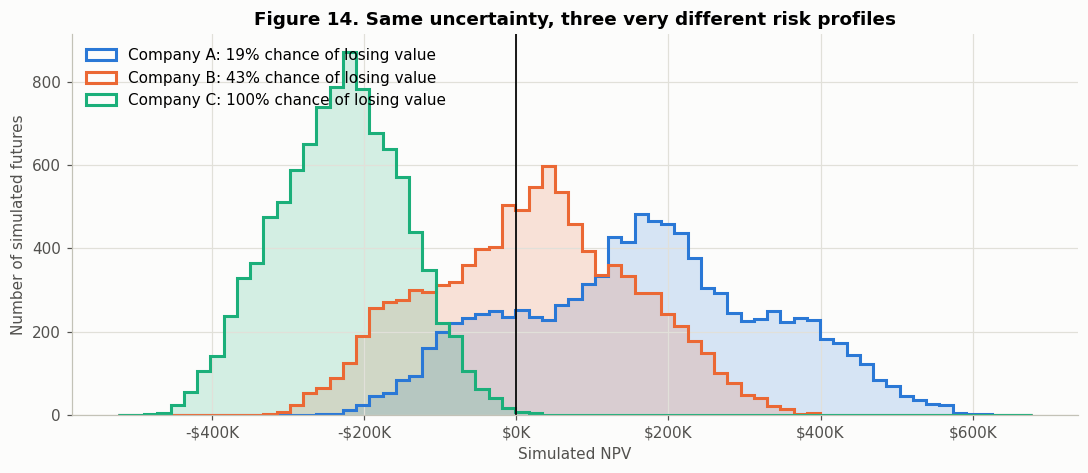

In [ ]:
rng = np.random.default_rng(7)
N = 10_000
lives = rng.choice([4, 5, 6], size=N, p=[0.25, 0.5, 0.25])
cash = rng.normal(ANNUAL, 0.15 * ANNUAL, size=(N, 6))

sims = {}
for name, r in WACCS.items():
    disc = 1 / (1 + r) ** np.arange(1, 7)
    mask = np.arange(1, 7)[None, :] <= lives[:, None]             # zero-out years past the instrument's life
    sims[name] = -OUTLAY + (cash * disc * mask).sum(axis=1)
sims = pd.DataFrame(sims)

risk = pd.DataFrame({"Mean NPV": sims.mean(), "5th percentile": sims.quantile(0.05),
                     "95th percentile": sims.quantile(0.95), "P(NPV < 0)": (sims < 0).mean()})
display(risk.style.format({"Mean NPV": "${:,.0f}", "5th percentile": "${:,.0f}", "95th percentile": "${:,.0f}",
                           "P(NPV < 0)": "{:.0%}"})
        .set_caption("Table 10. Simulated NPV by lab (10,000 runs)"))

fig, ax = plt.subplots(figsize=(10, 4.4))
bins = np.linspace(sims.min().min(), sims.max().max(), 70)
for name in WACCS:
    ax.hist(sims[name], bins=bins, color=COLORS[name], alpha=0.18)
    ax.hist(sims[name], bins=bins, color=COLORS[name], histtype="step", lw=2,
            label=f"{name}: {risk.loc[name, 'P(NPV < 0)']:.0%} chance of losing value")
ax.axvline(0, color=INK, lw=1.2)
ax.xaxis.set_major_formatter(thousands)
ax.set_xlabel("Simulated NPV"); ax.set_ylabel("Number of simulated futures")
ax.set_title("Figure 14. Same uncertainty, three very different risk profiles")
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

## 8. Handoff for lab managers

| Metric | Use it for | Watch out for | Role in the decision |
|---|---|---|---|
| **NPV** | Dollars of value created today | Needs a sound WACC and cash-flow forecast | **The decision** |
| IRR | Annual % return vs. WACC | Blind to scale | Hurdle check |
| Payback | How long cash is at risk | Ignores everything after breakeven | Liquidity / risk check |
| Simple ROI | Easy communication | Ignores time, cost of capital, scale | Informational only |

**Rule:** when requests compete for the same budget, bench or staff, fund the combination with the highest total positive NPV at your WACC.

### Export everything to Excel (for colleagues who don't code)

In [ ]:
with pd.ExcelWriter("Lab_Capital_Results.xlsx", engine="openpyxl") as xw:
    labs.to_excel(xw, sheet_name="WACC")
    s1.to_excel(xw, sheet_name="Scenario 1")
    pv.to_excel(xw, sheet_name="Scenario 1 PV")
    s2.drop(columns="Picks").to_excel(xw, sheet_name="Scenario 2")
    port.to_excel(xw, sheet_name="Portfolio")
    res.to_excel(xw, sheet_name="Budget rules")
    risk.to_excel(xw, sheet_name="Monte Carlo")
print("Saved Lab_Capital_Results.xlsx")

Saved Lab_Capital_Results.xlsx
